# Practical 5 - Histogram and Contrast Stretching

Aim: Plot grayscale and color histograms and enhance contrast using alpha, beta and gamma stretching.

Name: Navjot Singh
Roll No: 2025010071


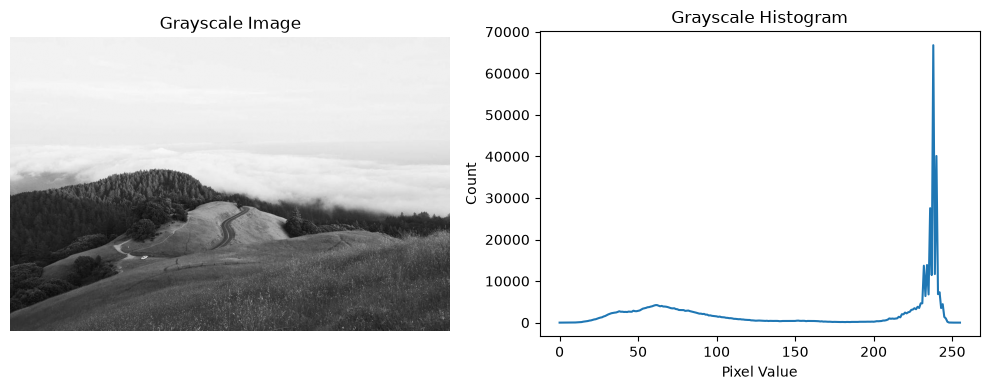

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Name: Navjot Singh")
print("Roll No: 2025010071")

img = cv2.imread("images/navjot_a.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# grayscale histogram
hist = cv2.calcHist([gray], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.plot(hist)
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Value")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

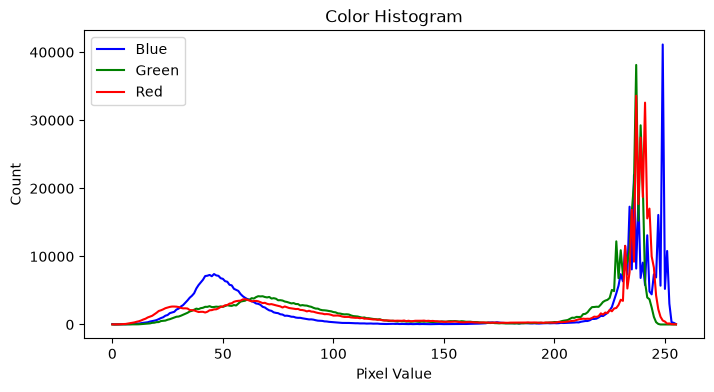

In [2]:
# histogram for each color channel
colors = ("b", "g", "r")
labels = ("Blue", "Green", "Red")

plt.figure(figsize=(8, 4))
for i in range(3):
    channel_hist = cv2.calcHist([img], [i], None, [256], [0, 256])
    plt.plot(channel_hist, color=colors[i], label=labels[i])

plt.title("Color Histogram")
plt.xlabel("Pixel Value")
plt.ylabel("Count")
plt.legend()
plt.show()

Alpha: 0.8636363636363636
Beta: 1.875
Gamma: 0.7216494845360825


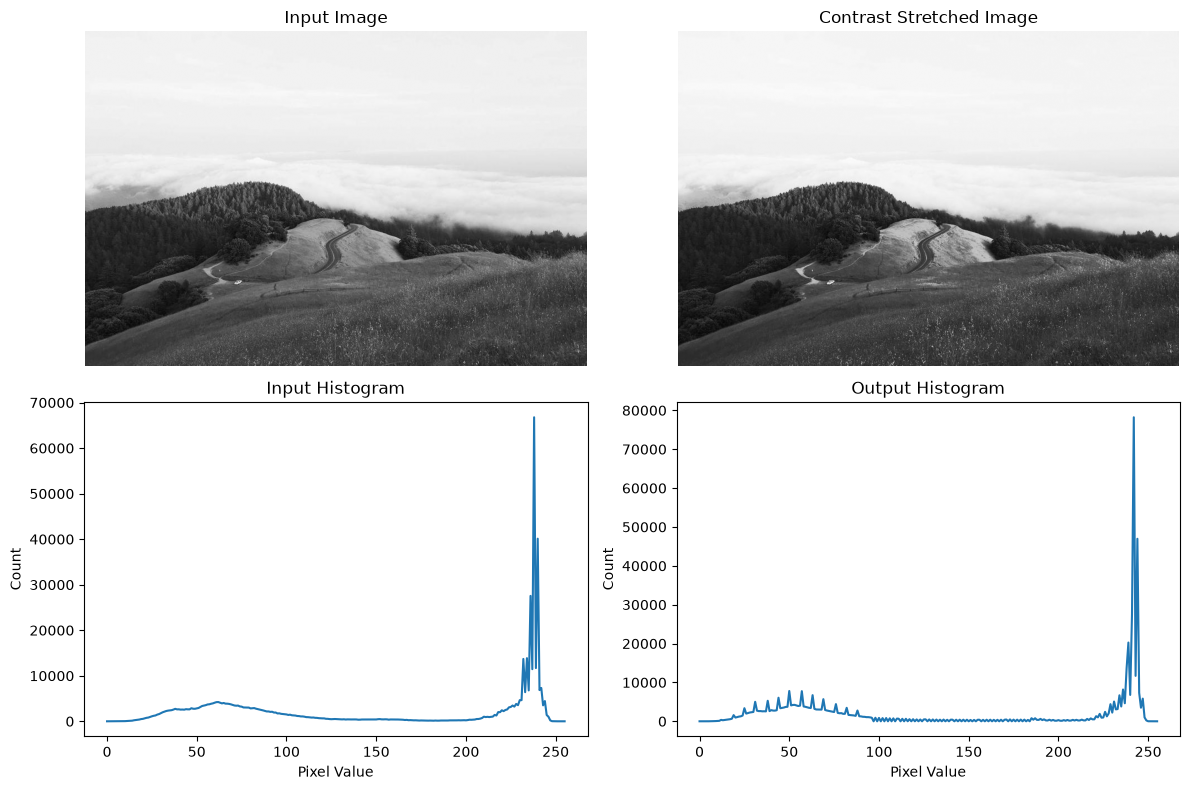

In [3]:
# alpha, beta and gamma for the three ranges
r1, r2 = 110, 158
s1, s2 = 95, 185

alpha = s1 / r1
beta = (s2 - s1) / (r2 - r1)
gamma = (255 - s2) / (255 - r2)

print("Alpha:", alpha)
print("Beta:", beta)
print("Gamma:", gamma)

stretched = np.zeros_like(gray)
for i in range(gray.shape[0]):
    for j in range(gray.shape[1]):
        r = int(gray[i, j])
        if r <= r1:
            s = alpha * r
        elif r <= r2:
            s = beta * (r - r1) + s1
        else:
            s = gamma * (r - r2) + s2
        stretched[i, j] = np.clip(s, 0, 255)

cv2.imwrite("output/lab5_contrast_stretched.jpg", stretched)

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Input Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(stretched, cmap="gray")
plt.title("Contrast Stretched Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.plot(cv2.calcHist([gray], [0], None, [256], [0, 256]))
plt.title("Input Histogram")
plt.xlabel("Pixel Value")
plt.ylabel("Count")

plt.subplot(2, 2, 4)
plt.plot(cv2.calcHist([stretched], [0], None, [256], [0, 256]))
plt.title("Output Histogram")
plt.xlabel("Pixel Value")
plt.ylabel("Count")

plt.tight_layout()
plt.show()